# 17 灰色关联分析

> **模块**：灰色系统 ｜ **数据**：无（内置示例） ｜ **依赖**：numpy、pandas、matplotlib

## 1. 问题背景

两个系统之间的因素，随时间或不同对象而变化的关联性大小的量度，称为关联度。两个因素变化即同步变化程度较高，即可谓二者关联程度较高；反之，则较低。因此，灰色关联分析方法，根据因素之间发展趋势的相似相异程度，为衡量因素间关联程度提供了量化的度量。

灰色关联分析的基本思想是根据序列曲线几何形状的相似程度来判断其联系是否紧密。曲线越接近，相应序列之间的关联度就越大，反之就越小。


## 2. 学习目标

- 掌握灰色关联度分析原理
- 掌握灰色关联度分析实现


## 3. 环境与数据

- Jupyter 开发环境
- Python 3.10


## 4. 方法与实现

### 4.1 灰色系统与灰色关联度分析

#### 4.1.1 灰色系统理论

概率统计、模糊数学、灰色系统理论和粗糙集理论是4种最常用的不确定系统研究方法，研究对象具有某种不确定性是它们共同的特点。灰色系统理论着重研究概率统计，模糊数学难以解决的“小样本，贫信息”不确定性问题，着重研究“外延明确，内涵不明确”的对象。

通常用“黑”“白”“灰”颜色的深浅形容对信息的了解程度，“黑色”表示信息未知、“白色”表示信息完全明确，“灰色”表示部分信息明确、部分信息不明确。

信息完全明确的系统称为白色系统；信息未知的系统称为黑色系统；部分信息明确，部分不明确的系统称为灰色系统。

**灰色系统是指部分信息已知而部分信息未知的系统**。

#### 4.1.2 灰色关联度分析

灰色系统理论提出了一种新的分析方法—关联度分析方法，即根据因素之间发展态势的相似或相异程度来衡量因素间关联的程度，它揭示了事物动态关联的特征与程度。由于以发展态势为立足点，因此对样本量的多少没有过分的要求，也不需要典型的分布规律，计算量少到甚至可用手算，且不致出现关联度的量化结果与定性分析不一致的情况。这种方法已应用到农业经济、水利、宏观经济等各方面，都取得了较好的效果。

灰色关联分析是一种基于灰色系统理论的分析方法，它可以用于研究多个因素之间的关联程度。**该方法通常用于分析复杂系统或过程，其中因素之间的关联关系不是完全清晰或无法用精确的数学模型描述**。

例1.下表为某地区1997-2003年总收入（亿元）、招商引资收入（亿元）、和农业收入（亿元）。

|  项目   | 1997  |  1998   | 1999  |  2000   | 2001  | 2002  | 2003  |
|  :---: |:---: |:---: |:---: |:---: |:---: |:---: |:---: |
| 总收入   | 18  |  20   | 22  |  40   | 44  | 48  | 60  |
| 招商引资收入   | 10  |  15   | 16  |  24   | 38  |  40   | 50  |
| 农业收入   | 3  |  2   | 12  |  10   | 22  | 18   | 20  |

先将上表数据绘制成图像。


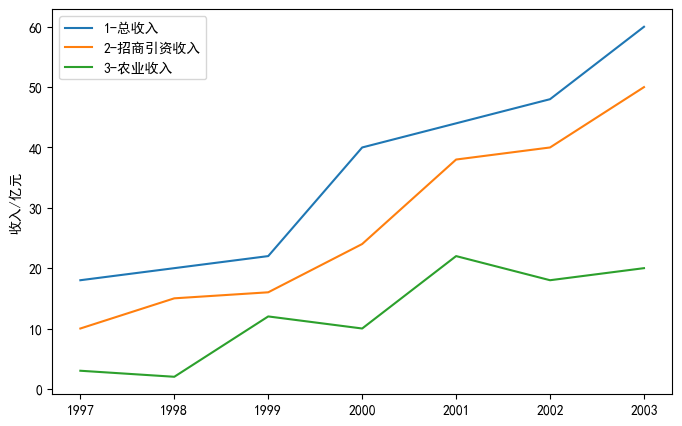

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# 用来正常显示中文标签
plt.rcParams['font.sans-serif']=['SimHei'] 
# 正常显示负号
plt.rc('axes',unicode_minus=False)
# 忽略警告提示
import warnings
warnings.filterwarnings('ignore')

# 创建数据
data = np.array([[18,20,22,40,44,48,60],
                 [10,15,16,24,38,40,50],
                 [3,2,12,10,22,18,20]])
data = pd.DataFrame(data = data.T,index = range(1997,2004),columns = ['1-总收入','2-招商引资收入','3-农业收入'])
# 直接使用pandas绘图
data.plot(figsize = (8,5))
# 显示图例
plt.legend()
# 设置y轴标签
plt.ylabel('收入/亿元')
plt.show()

灰色关联分析是一种多因素统计方法，用灰色关联度来描述因素间关系的强弱、大小和次序。

从思路上看，关联度分析时属于集合处理范畴的。它是一种相对性的排序分析，基本思想是根据序列曲线几何形状的相似程度来判断其联系是否紧密，曲线越接近，相应序列之间的关联度就越大，反之就越少。

从上图可以看出曲线2的形状与曲线1的形状较为接近，而曲线3与曲线1相差较大，因此该地区对收入影响较大的是招商引资，在指定该地区经济发展规划时，显然应加大招商引资的力度。

所以，几何形状越接近，关联程度也就越大。直观分析几何形状对于稍微复杂的问题就比较困难了，因此，需要一种计算方法来衡量因素间关联程度的大小。

### 4.2 灰色关联度分析算法实现

#### 4.2.1 关联分析一般步骤

- 确定参考指标和比较指标，一般参考指标放最开始的位置。

关联分析之前先要指定参考指标和比较指标。

参考数据列常记为$x_0$，一般表示为：$x_0 = \{x_0(1), x_0(2), \dots, x_0(n)\}$；

比较数据列常记为$x_i$，一般表示为：$x_i = \{x_i(1), x_i(2), \dots, x_i(n)\} \ (i = 1, 2, \dots, m)$。

2. 对参考指标和比较指标进行无量纲化处理

由于系统中各因素列中的数据可能因量纲不同，不便于比较或在比较时难以得到正确的结论。因此在进行灰色关联度分析时，一般都要进行数据的无量纲处理。
这里介绍常用的两种：

**定义1**. 设有序列$x = \{x(1), x(2), \dots, x(n)\}$，则称映射

$$f: x \rightarrow y$$

$$f(x(k)) = y(k), \ k=1, 2, \dots, n$$
为序列$x$到序列$y$的数据变换

（1）初值变换：$$f(x(k)) = \frac{x(k)}{x(1)}=y(k), \ x(1)\neq0$$

（2）均值变换：$$f(x(k)) = \frac{x(k)}{\overline{x}}=y(k), \ \overline{x}=\frac{1}{n}\sum_{k=1}^{n}x(k)$$

3. 计算关联系数

$$\xi_i(k) = \frac{\underset{s}{min}\underset{t}{min}|x_0(t)-x_s(t)|+\rho \underset{s}{max}\underset{t}{max}|x_0(t)-x_s(t)|}{|x_0(k)-x_i(k)|+\rho \underset{s}{max}\underset{t}{max}|x_0(t)-x_s(t)|}$$

$\xi_i(k)$为比较数列$x_i$对参考数列$x_0$在$k$时刻的关联系数，其中$\rho \in [0,1]$为分辨系数。上式中$\underset{s}{min} \underset{t}{min} |x_0(t)-x_s(t)|$、$\underset{s}{max}\underset{t}{max}|x_0(t)-x_s(t)|$分别为两级最小差及两级最大差。

一般来说，分辨系数$\rho$越大，分辨率越大；$\rho$越小，分辨率越小。当$\rho \leq 0.5463$时，分辨力最好，通常取$\rho=0.5$。

4. 计算关联度

因为关联系数是比较数列与参考数量在各个时刻（即曲线中的各点）的关联程度值，所以它的数不止一个，而信息过于分散不便于进行整体性比较。因此有必要将各个时刻（即曲线中的各点）的关联系数集中为一个值，即求平均值，作为比较数列与参考数列间关系程度的数量表示。关联度公式如下：

$$r_i = \frac{1}{n}\sum_{k=1}^{n}\xi_i(k)$$
$r_i$表示数列$x_i$对参考数列$x_0$的关联度。

5. 关联度排序
关联度按大小排序，如果$r_1 < r_2$则参考列$x_0$与比较数列$x_2$更相似。

#### 4.2.2 灰色关联度分析算法实现

**例2**.通过对某健将级女子铅球运动员的跟踪调查，获得其1982年至1986年每年最好成绩及16项专项素质和身体素质的时间序列资料，见下表，试对此铅球运动员的专项成绩进行关联度分析。

> *原稿配图未随 notebook 保存，此处暂缺。*

##### 4.2.2.1 创建数据


In [2]:
# 创建数据
x = np.array([
    [13.6,14.01,14.54,15.64,15.69],
    [11.50,13.00,15.15,15.30,15.02],
    [13.76,16.36,16.90,16.56,17.30],
    [12.41,12.70,13.96,14.04,13.46],
    [2.48,2.49,2.56,2.64,2.59],
    [85,85,90,100,105],
    [55,65,75,80,80],
    [65,70,75,85,90],
    [12.80,15.30,16.24,16.40,17.05],
    [15.30,18.40,18.75,17.95,19.30],
    [12.71,14.50,14.66,15.88,15.70],
    [14.78,15.54,16.03,16.87,17.82],
    [7.64,7.56,7.76,7.54,7.70],
    [120,125,130,140,140],
    [80,85,90,90,95],
    [4.2,4.25,4.1,4.06,3.99],
    [13.1,13.42,12.85,12.72,12.56]
])
x

array([[ 13.6 ,  14.01,  14.54,  15.64,  15.69],
       [ 11.5 ,  13.  ,  15.15,  15.3 ,  15.02],
       [ 13.76,  16.36,  16.9 ,  16.56,  17.3 ],
       [ 12.41,  12.7 ,  13.96,  14.04,  13.46],
       [  2.48,   2.49,   2.56,   2.64,   2.59],
       [ 85.  ,  85.  ,  90.  , 100.  , 105.  ],
       [ 55.  ,  65.  ,  75.  ,  80.  ,  80.  ],
       [ 65.  ,  70.  ,  75.  ,  85.  ,  90.  ],
       [ 12.8 ,  15.3 ,  16.24,  16.4 ,  17.05],
       [ 15.3 ,  18.4 ,  18.75,  17.95,  19.3 ],
       [ 12.71,  14.5 ,  14.66,  15.88,  15.7 ],
       [ 14.78,  15.54,  16.03,  16.87,  17.82],
       [  7.64,   7.56,   7.76,   7.54,   7.7 ],
       [120.  , 125.  , 130.  , 140.  , 140.  ],
       [ 80.  ,  85.  ,  90.  ,  90.  ,  95.  ],
       [  4.2 ,   4.25,   4.1 ,   4.06,   3.99],
       [ 13.1 ,  13.42,  12.85,  12.72,  12.56]])

参考数据列为铅球专项成绩$x_0$，比较数据列为$x_1—x_{16}$。

##### 4.2.2.2 无量纲化处理

本次实验我们对数据列进行无量纲化处理，通过初值变换的方式实现。

$$
f(x(k)) = \frac{x(k)}{x(1)}=y(k), \quad x(1) \neq 0

$$

**注意：对于变量 $x_0 - x_{14}$，随着时间的增加，数值的提升意味着运动水平的进步；而对于 $x_{15}$ 和 $x_{16}$，随着时间的推移，数值（秒数）的减少却表示运动水平的提高。**

因此，对于 $x_{15}$ 和 $x_{16}$，我们采用以下公式进行处理：

$$
f(x(k)) = \frac{x(1)}{x(k)}=y(k), \quad x(k) \neq 0

$$

In [3]:
# 无量纲化处理：前15个数据列和后两个数据列分别处理
for i in range(15):
    x[i] = x[i]/x[i,0]
for i in range(15,17):
    x[i] = x[i,0]/x[i]
x

array([[1.        , 1.03014706, 1.06911765, 1.15      , 1.15367647],
       [1.        , 1.13043478, 1.3173913 , 1.33043478, 1.30608696],
       [1.        , 1.18895349, 1.22819767, 1.20348837, 1.25726744],
       [1.        , 1.02336825, 1.12489927, 1.13134569, 1.08460919],
       [1.        , 1.00403226, 1.03225806, 1.06451613, 1.04435484],
       [1.        , 1.        , 1.05882353, 1.17647059, 1.23529412],
       [1.        , 1.18181818, 1.36363636, 1.45454545, 1.45454545],
       [1.        , 1.07692308, 1.15384615, 1.30769231, 1.38461538],
       [1.        , 1.1953125 , 1.26875   , 1.28125   , 1.33203125],
       [1.        , 1.20261438, 1.2254902 , 1.17320261, 1.26143791],
       [1.        , 1.14083399, 1.1534225 , 1.24940991, 1.23524784],
       [1.        , 1.05142084, 1.08457375, 1.14140731, 1.20568336],
       [1.        , 0.9895288 , 1.01570681, 0.98691099, 1.0078534 ],
       [1.        , 1.04166667, 1.08333333, 1.16666667, 1.16666667],
       [1.        , 1.0625    , 1.

##### 4.2.2.3 计算关联系数

$$
\xi_i(k) = \frac{\min_{s}\min_{t}|x_0(t)-x_s(t)| + \rho \max_{s}\max_{t}|x_0(t)-x_s(t)|}{|x_0(k)-x_i(k)| + \rho \max_{s}\max_{t}|x_0(t)-x_s(t)|}

$$

In [4]:
# 获取观测时刻数
n = x.shape[1]
# 提取参考列x1和比较列xi
x0 = x[0]
xi = x[1::]
# 获取比较列个数
n2 = xi.shape[0]
# 创建一个全0数组与xi形状相同
t = np.zeros((xi.shape))
# 计算xi(t)-x0(t)
for i in range(n2):
    t[i] = xi[i]-x0
# 计算两级最小差及两级最大差
mi = np.min(np.min(abs(t),axis = 0))
ma = np.max(np.max(abs(t),axis = 0))
# 设置分辨系数
rho = 0.5
# 求关联系数
kxi = (mi+rho*ma)/(abs(t)+rho*ma)
print('关联系数为：\n',kxi)

关联系数为：
 [[1.         0.60291596 0.38016253 0.45767746 0.49977393]
 [1.         0.48949833 0.48906819 0.74004624 0.59513221]
 [1.         0.95737981 0.73188916 0.8908639  0.68795843]
 [1.         0.85360635 0.80511219 0.64045637 0.58209484]
 [1.         0.834738   0.93667763 0.85190726 0.65104316]
 [1.         0.50098966 0.34081388 0.33333333 0.33603776]
 [1.         0.7650022  0.64249761 0.49125776 0.39735935]
 [1.         0.47969256 0.43270966 0.53707415 0.46055674]
 [1.         0.46890653 0.49335836 0.86777279 0.58558739]
 [1.         0.57907258 0.64364817 0.60501879 0.65117201]
 [1.         0.87741741 0.90785066 0.94658459 0.74541324]
 [1.         0.78942374 0.74032519 0.482851   0.5108181 ]
 [1.         0.92966943 0.91461456 0.90134529 0.92139679]
 [1.         0.82476466 0.731535   0.85897436 0.81824713]
 [1.         0.78416523 0.77295749 0.56862745 0.60111384]
 [1.         0.73823906 0.75406757 0.55900719 0.57908159]]


##### 4.2.2.4 计算关联度

$$r_i = \frac{1}{n}\sum_{k=1}^{n}{\xi_i(k)}$$
$r_i$表示数列$x_i$对参考数列$x_0$的关联度。

影响铅球专项成绩的影响因素前八项和关联度：
           关联度
r13  0.933405
r11  0.895453
r5   0.854873
r3   0.853618
r14  0.846704
r4   0.776254
r15  0.745373
r16  0.726079


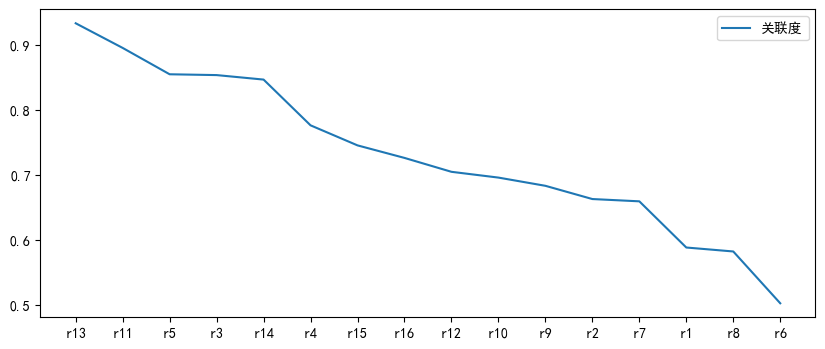

In [5]:
# 计算关联度
r1 = np.sum(kxi,axis =1)/n
r = pd.DataFrame(r1,index = ['r1','r2','r3','r4','r5','r6','r7','r8','r9','r10','r11','r12','r13','r14','r15','r16'],
                 columns =['关联度'])
# 将关联度降序排列
r_sort = r.sort_values(by = '关联度',ascending=False)
# 绘图
r_sort.plot(figsize=(10,4))
# 设置x轴刻度值
plt.xticks(range(len(r_sort.index)),r_sort.index.values)
print('影响铅球专项成绩的影响因素前八项和关联度：\n',r_sort[:8])

影响铅球专项成绩的前八项主要因素一次为全蹲、3kg滑步、高翻、4kg原地、挺举、立定跳远、30米起跑和100米成绩。因此，在训练中应着重考虑安排这八项指标的练习。这样可减少训练的盲目性，提高训练效果。


### 4.3 灰色关联度计算

> 来源：教材参考实现《数学建模算法与应用》14.4 节的练习稿（MIT，Zhanghan Wang），代码保持原样，仅按需改写数据路径并清空输出。

[参考链接](https://www.cnblogs.com/aabbcc/p/9747715.html)

In [ ]:
import numpy as np


data = np.loadtxt('../data/textbook/14.D 供应商选择决策.txt')
# 效益型指标标准化
for index in [0]+[i for i in range(4, 9)]:
    data[index] = (data[index] - np.min(data[index])) / (np.max(data[index]) - np.min(data[index]))
# 成本型指标标准化
for index in [i for i in range(1, 4)]:
    data[index] = (np.max(data[index]) - data[index]) / (np.max(data[index]) - np.min(data[index]))

best = np.array([np.max(data[index]) for index in range(data.shape[0])])
# 由于做了scale上句和下句等效
# best = np.ones(data.shape[0])

mmax = np.max(data.max(axis=1))
mmin = np.min(data.min(axis=1))
rho = 0.5
GRC = np.divide((mmin + rho * mmax), ((np.array([best]).T - data) + rho * mmax))
print('灰色关联系数矩阵:', GRC, sep='\n')

# 计算灰色加权关联度, 取等权重
w = np.ones(GRC.shape[0])/GRC.shape[0]
R = np.matmul(w, GRC)
print('灰色加权关联度: ', R)

## 5. 小结

本次实验介绍了灰色系统理论和灰色关联分析的原理和一般步骤。基于一个例子，使用Python实现了对数据的灰色关联分析。

通过本次实验需要掌握以下内容：
- 掌握灰色关联度分析原理
- 掌握灰色关联度分析实现
